In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import sys
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import regionmask
import seaborn as sns
import xarray as xr

sys.path.append("../..")

from src.conversion_energy.pv import (
    NORMALISED_ROOFTOP_PV_CONFIGURATION,
)
from src.utils.utils_xarray import sel_extent
from src.conversion_energy.plots import plot_yearly_mean_boxplot

sns.set_style("whitegrid", {"grid.color": ".93"})

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/bias_correction_2024/share/proj failed


In [3]:
paths = json.load(open("../../paths_so4.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_data_cerra = Path(paths["path_data_cerra"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])
path_data_personal = Path(paths["path_data_personal"])
path_data_personal_cordex = path_data_personal / "cordex"
path_data_temporary = Path(paths["path_data_temporary"])

path_energy_ch = path_data_processed / "energy" / "ch"
path_energy_europe = path_data_processed / "energy" / "europe"

path_figs = Path(paths["path_figs"])

In [4]:
extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 30}
extent_ch = {"lat_min": 45.8, "lat_max": 47.9, "lon_min": 5.9, "lon_max": 10.5}

In [5]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

In [6]:
azimuths = {"E": 90, "SE": 135, "S": 180, "SW": 225, "W": 270, "N": 0}
tilts = [3, 8, 15, 25, 35, 45, 60, 80, 90]

# Switzerland

## Load data

In [7]:
path_pv = path_energy_ch / "pv" / f"pv_{climate_model_chain}_{climate_scenario}.zarr"
ds_pv = xr.open_zarr(path_pv, chunks="auto") / (1 - 0.14)
if climate_scenario == "rcp85":
    ds_pv /= NORMALISED_ROOFTOP_PV_CONFIGURATION["module_parameters"]["pdc0"]

In [8]:
path_pv = path_energy_ch / "pv" / f"pv_{climate_model_chain}_rcp26.zarr"
ds_pv_rcp26 = xr.open_zarr(path_pv, chunks="auto") / (1 - 0.14)

In [12]:
ds_orog = sel_extent(
    xr.open_dataset(
        sorted(
            (
                path_data_processed
                / "cordex_processed"
                / f"{climate_model_chain}_{climate_scenario}"
                / "regridded"
                / "fx"
            ).glob("*.nc")
        )[0]
    ),
    extent_ch,
)

In [13]:
gdf_regions_ch = gpd.read_file(
    path_data_processed / "maps" / "regions_ch" / "PRODREG.shp"
).to_crs("EPSG:4326")
regions_ch = regionmask.from_geopandas(gdf_regions_ch, names="ProdregN_3")
regions_ch_mask = regions_ch.mask(ds_orog.orog)

In [14]:
maps_base_dir = Path("/net/exo/landclim/yhaddad/maps/")
gdf_cantons = gpd.read_file(
    maps_base_dir
    / "swissboundaries3d_2025-04_2056_5728"
    / "swissBOUNDARIES3D_1_5_TLM_KANTONSGEBIET.shp",
    engine="pyogrio",
).to_crs("EPSG:4326")
gdf_cantons.loc[gdf_cantons["NAME"] == "Basel-Stadt", "geometry"] = gdf_cantons.loc[
    gdf_cantons["NAME"] == "Basel-Stadt", "geometry"
].apply(lambda geom: geom.buffer(0.008, cap_style=3, resolution=16))
cantons_ch = regionmask.from_geopandas(gdf_cantons, names="NAME", overlap=False)
cantons_ch_mask = cantons_ch.mask(ds_orog.orog)

/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/pyogrio/geopandas.py:49: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  res = pd.to_datetime(ser, **datetime_kwargs)
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/pyogrio/geopandas.py:49: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  res = pd.to_datetime(ser, **datetime_kwargs)


In [16]:
ds_pv.sel(time=slice("2018", "2052")).to_netcdf(path_energy_ch / "pv" / f"pv_{climate_model_chain}_rcp85_all_tilts_azimuths.nc")
ds_pv_rcp26.sel(time=slice("2018", "2052")).to_netcdf(path_energy_ch / "pv" / f"pv_{climate_model_chain}_rcp26_all_tilts_azimuths.nc")

# Europe

In [9]:
path_pv = (
    path_energy_europe
    / "pv"
    / f"{climate_model_chain}_{climate_scenario}"
    / f"pv_{climate_model_chain}_{climate_scenario}.zarr"
)

path_pv_agg = (
    path_energy_europe
    / "pv"
    / f"{climate_model_chain}_{climate_scenario}"
    / f"pv_agg_{climate_model_chain}_{climate_scenario}.nc"
)

ds_pv_rcp26 = xr.open_zarr(
    str(path_pv).replace(climate_scenario, "rcp26"), chunks="auto"
)
ds_pv_rcp85 = xr.open_zarr(
    str(path_pv).replace(climate_scenario, "rcp85"), chunks="auto"
)

ds_pv_agg_rcp26 = xr.open_dataset(str(path_pv_agg).replace(climate_scenario, "rcp26"))
ds_pv_agg_rcp85 = xr.open_dataset(str(path_pv_agg).replace(climate_scenario, "rcp85"))

In [7]:
ds_orog = sel_extent(
    xr.open_dataset(
        sorted(
            (
                path_data_temporary
                / "cordex_processed"
                / f"{climate_model_chain}_{climate_scenario}"
                / "regridded"
                / "fx"
            ).glob("*.nc")
        )[0]
    ),
    extent,
)

## Analysis

### Entire grid

In [8]:
selected_var = "tilt_35_azimuth_S"
reference_period = slice("1991", "2020")
future_period = slice("2021", "2050")

In [9]:
# Calculate the mean values for the future period
mean_future = (ds_pv_rcp26[selected_var]).sel(time=future_period).mean(dim="time")

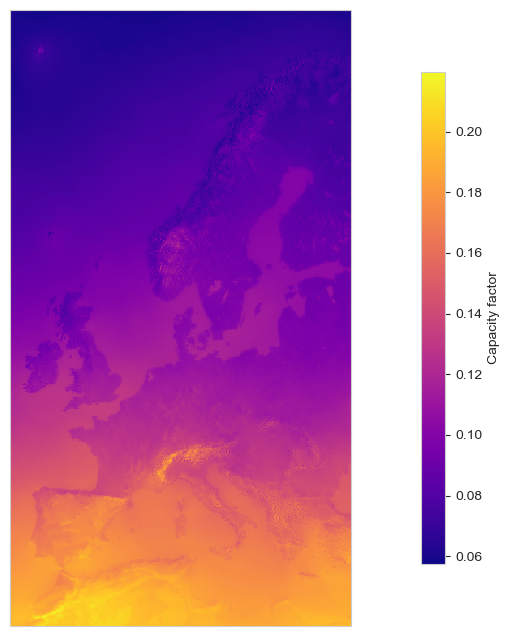

In [10]:
proj = ccrs.Mercator(central_longitude=10.0, min_latitude=30.0, max_latitude=75.0)
fig, axes = plt.subplots(figsize=(18, 8), subplot_kw={"projection": proj})
mean_future.plot(
    ax=axes,
    cmap="plasma",
    transform=ccrs.PlateCarree(),
    cbar_kwargs={
        "label": "Capacity factor",
        "shrink": 0.8,
        "orientation": "vertical",
        "pad": 0.05,
        "aspect": 20,
    },
)
plt.show()

### Country aggregates

In [11]:
yearly_aggregated_future_rcp26 = (
    ds_pv_agg_rcp26.sel(time=future_period)
    .resample(time="1YE")
    .mean()
)

yearly_aggregated_future_rcp85 = (
    ds_pv_agg_rcp85.sel(time=future_period)
    .resample(time="1YE")
    .mean()
)

In [12]:
yearly_aggregated_future_rcp85

<xarray.Dataset> Size: 10kB
Dimensions:            (time: 30, country: 30)
Coordinates:
  * country            (country) <U22 3kB 'France' ... 'Bosnia and Herzegovina'
  * time               (time) datetime64[ns] 240B 2021-12-31 ... 2050-12-31
Data variables:
    tilt_35_azimuth_S  (time, country) float64 7kB 0.1504 0.1005 ... 0.1533

In [ ]:
# plot_yearly_mean_boxplot([yearly_aggregated_future_rcp26, yearly_aggregated_future_rcp85], ["RCP2.6, RCP8.5"], selected_var=selected_var, regions_to_plot=)

# Comparison with CESM

In [13]:
ds_cesm = xr.open_mfdataset(
    sorted(
        Path(
            "/net/xenon/climphys/lbloin/CESM2energy/output/bias_correction/A/SSP370/A/output_variables/"
        ).glob("PV*.nc")
    )
)

In [14]:
df_cesm_single_year = pd.read_csv(
    sorted(
        Path(
            "/net/xenon/climphys/lbloin/CESM2energy/output/bias_correction/A/SSP370/A/output_variables/"
        ).glob("PV*.csv")
    )[0],
)

In [15]:
list_files_cesm = sorted(
    Path(
        "/net/xenon/climphys/lbloin/CESM2energy/output/bias_correction/A/SSP370/A/output_variables/"
    ).glob("PV*.csv")
)
df_cesm = pd.concat(
    [
        pd.read_csv(file).rename({"country": f"country_{i}"}, axis=1)
        for i, file in enumerate(list_files_cesm)
    ],
    axis=1,
).drop(columns=[f"country_{i}" for i in range(len(list_files_cesm)) if i > 0])
df_cesm = df_cesm.rename({"country_0": "country"}, axis=1)
df_cesm = df_cesm.T
df_cesm.columns = df_cesm.iloc[0].tolist()
df_cesm = df_cesm[1:]
df_cesm.index = pd.to_datetime(df_cesm.index)
df_cesm.head()

,Albania,Austria,Bosnia and Herzegovina,Belgium,Bulgaria,Switzerland,Czech Republic,Germany,Denmark,Estonia,...,Netherlands,Norway,Poland,Portugal,Romania,Serbia,Sweden,Slovenia,Slovakia,United Kingdom
2080-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2080-01-01 02:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2080-01-01 03:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2080-01-01 04:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2080-01-01 05:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [16]:
# Group by month and calculate the mean over the entire period
df_cesm_monthly_mean = df_cesm.groupby(df_cesm.index.month).mean()
df_cesm_monthly_mean

,Albania,Austria,Bosnia and Herzegovina,Belgium,Bulgaria,Switzerland,Czech Republic,Germany,Denmark,Estonia,...,Netherlands,Norway,Poland,Portugal,Romania,Serbia,Sweden,Slovenia,Slovakia,United Kingdom
1,0.114172,0.10912,0.092058,0.060651,0.111025,0.116204,0.070047,0.072122,0.040944,0.029921,...,0.053875,0.026621,0.055139,0.119743,0.09209,0.099849,0.031469,0.094225,0.070755,0.04913
2,0.152575,0.138639,0.134412,0.082813,0.152054,0.1401,0.104026,0.099325,0.072887,0.06238,...,0.078617,0.067555,0.086503,0.157778,0.130565,0.146849,0.06841,0.129268,0.107097,0.073369
3,0.169202,0.156803,0.155557,0.117437,0.165247,0.16689,0.134149,0.131919,0.125573,0.123577,...,0.118043,0.128969,0.125575,0.185885,0.155135,0.15723,0.118681,0.153623,0.138094,0.115194
4,0.200886,0.177667,0.186909,0.159321,0.186307,0.187854,0.170095,0.164783,0.170001,0.171904,...,0.161865,0.168142,0.162974,0.206211,0.180948,0.185029,0.162022,0.173823,0.172714,0.154722
5,0.205453,0.183637,0.195847,0.178276,0.191246,0.190653,0.18208,0.18081,0.201545,0.201884,...,0.185068,0.182482,0.182555,0.208189,0.187149,0.191794,0.188718,0.181741,0.184551,0.180341
6,0.206333,0.186234,0.194832,0.183922,0.192474,0.19906,0.183225,0.185666,0.207369,0.211764,...,0.18761,0.183799,0.184472,0.212323,0.186612,0.189346,0.197221,0.181607,0.183998,0.185759
7,0.215318,0.192929,0.205356,0.185227,0.203711,0.212361,0.183371,0.185444,0.192553,0.197343,...,0.178515,0.161709,0.183058,0.218596,0.196169,0.202205,0.185113,0.189347,0.187995,0.169271
8,0.211683,0.187118,0.200646,0.171766,0.201107,0.20821,0.17622,0.175369,0.169,0.164796,...,0.16048,0.128703,0.170278,0.21493,0.191852,0.200693,0.154566,0.18339,0.181273,0.149786
9,0.202796,0.181297,0.190178,0.14932,0.200517,0.1932,0.16224,0.158329,0.137839,0.140247,...,0.139459,0.105621,0.154274,0.205244,0.186502,0.19808,0.13172,0.17552,0.168941,0.128635
10,0.172146,0.150912,0.155275,0.106977,0.166489,0.157313,0.126884,0.121227,0.094387,0.086204,...,0.099507,0.075758,0.112161,0.176802,0.151548,0.166023,0.089195,0.140566,0.132301,0.097729


In [17]:
df_pv_agg_rcp26 = (
    ds_pv_agg_rcp26["tilt_35_azimuth_S"]
    .to_dataframe()
    .reset_index()
    .pivot(index="time", columns="country", values="tilt_35_azimuth_S")
)
df_pv_agg_rcp26_monthly_mean = df_pv_agg_rcp26.groupby(
    df_pv_agg_rcp26.index.month
).mean()

df_pv_agg_rcp85 = (
    ds_pv_agg_rcp85["tilt_35_azimuth_S"]
    .to_dataframe()
    .reset_index()
    .pivot(index="time", columns="country", values="tilt_35_azimuth_S")
)
df_pv_agg_rcp85_monthly_mean = df_pv_agg_rcp85.groupby(
    df_pv_agg_rcp85.index.month
).mean()

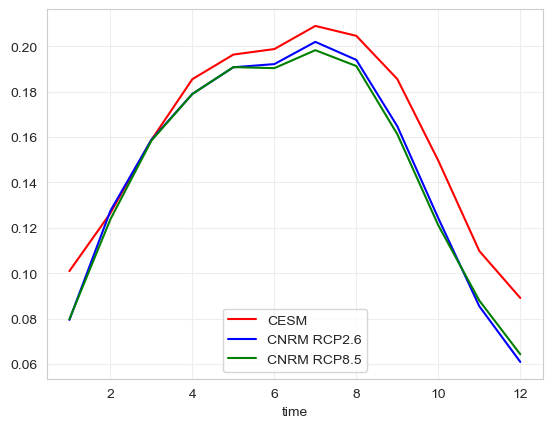

In [18]:
df_cesm_monthly_mean["France"].plot(color="red", label="CESM")
df_pv_agg_rcp26_monthly_mean["France"].plot(color="blue", label="CNRM RCP2.6")
df_pv_agg_rcp85_monthly_mean["France"].plot(color="green", label="CNRM RCP8.5")
plt.legend()

ValueError: Dataset.plot cannot be called directly. Use an explicit plot method, e.g. ds.plot.scatter(...)

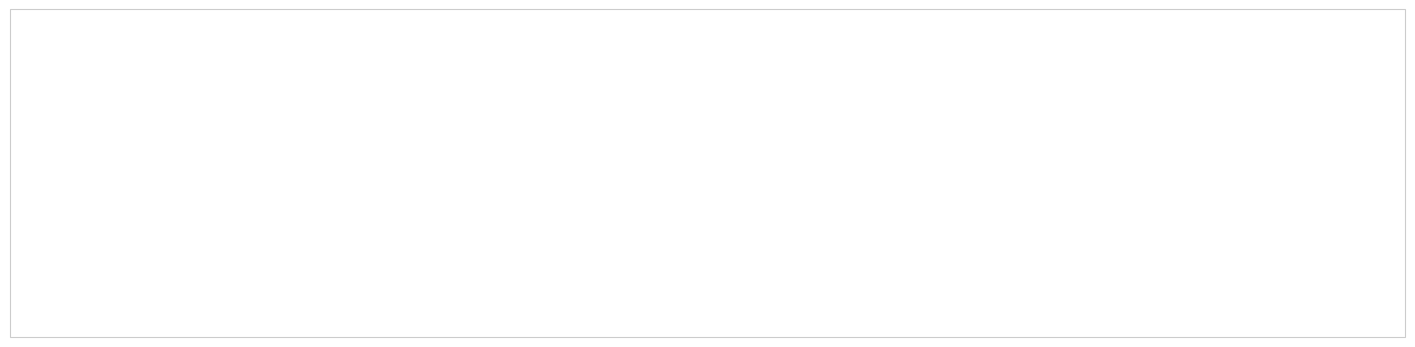

In [19]:
# Calculate the mean values for the future period
mean_cesm = ds_cesm.sel(time=future_period).mean(dim="time")
proj = ccrs.Mercator(central_longitude=10.0, min_latitude=30.0, max_latitude=75.0)
fig, axes = plt.subplots(figsize=(18, 8), subplot_kw={"projection": proj})
mean_cesm.plot(
    ax=axes,
    cmap="plasma",
    transform=ccrs.PlateCarree(),
    cbar_kwargs={
        "label": "Capacity factor",
        "shrink": 0.8,
        "orientation": "vertical",
        "pad": 0.05,
        "aspect": 20,
    },
)
plt.show()